# ⏳ Dove si vive di più (e in buona salute)?

Progetto di **Francesco Autorino** – Data Analyst.

❓ **La domanda**: quanti anni si vive in Italia, provincia per provincia, e quanti di questi in buona salute?

Le 5 domande più piccole:

1️⃣ 🗺️ Quanti anni si vive in ogni provincia?

2️⃣ 💚 Quanti di questi anni sono in buona salute?

3️⃣ ⚖️ Quanto è grande la distanza tra Nord e Sud? E tra uomini e donne?

4️⃣ 📈 Come è cambiata dal 2010 a oggi, Covid compreso?

5️⃣ 🚬 Gli stili di vita (sport, peso, fumo) c'entrano?

📊 Dati ISTAT: tavole di mortalità (107 province, 2010-2024), indicatori BES (21 regioni), BES dei territori.

📌 **Speranza di vita** = quanti anni vive in media chi nasce oggi, se la mortalità resta quella di quell'anno.

📌 **Anni in buona salute** = la parte di quegli anni in cui le persone dicono di stare bene o molto bene.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from pathlib import Path

DATI = Path("../02Dati/2Puliti")
GRAFICI = Path("Grafici"); GRAFICI.mkdir(exist_ok=True)
leggi = lambda f: pd.read_csv(DATI / f, keep_default_na=False, na_values=[""])   # "NA" = Napoli!
p = leggi("province.csv")
pa = leggi("province_anni.csv")
reg = leggi("regioni.csv")
ra = leggi("regioni_anni.csv")
za = leggi("italia_zone_anni.csv")

# colori del progetto: lavanda, salvia, corallo, inchiostro
LAVANDA, SALVIA, CORALLO, SABBIA, INCHIOSTRO = "#6C5B9E", "#7FA88B", "#E07A5F", "#E8D9B5", "#2D2A3E"
ZONE = {"Nord": "#4C6EB1", "Centro": SALVIA, "Sud": CORALLO, "Isole": "#D9A441"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 13, "font.size": 10})

def salva(nome):
    plt.tight_layout(); plt.savefig(GRAFICI / f"{nome}.png", bbox_inches="tight"); plt.show()

anni = lambda v: f"{v:.1f} anni".replace(".", ",")
it = za[(za.territorio == "Italia") & (za.sesso == "T")].set_index("anno")
print(f"Italia 2024: {anni(it.loc[2024, 'speranza_vita'])} · province: {len(p)} · regioni: {len(reg)}")

Italia 2024: 83,5 anni · province: 107 · regioni: 21


## 1️⃣ 🗺️ Quanti anni si vive in ogni provincia?

📌 Speranza di vita alla nascita nel **2024**, uomini e donne insieme.

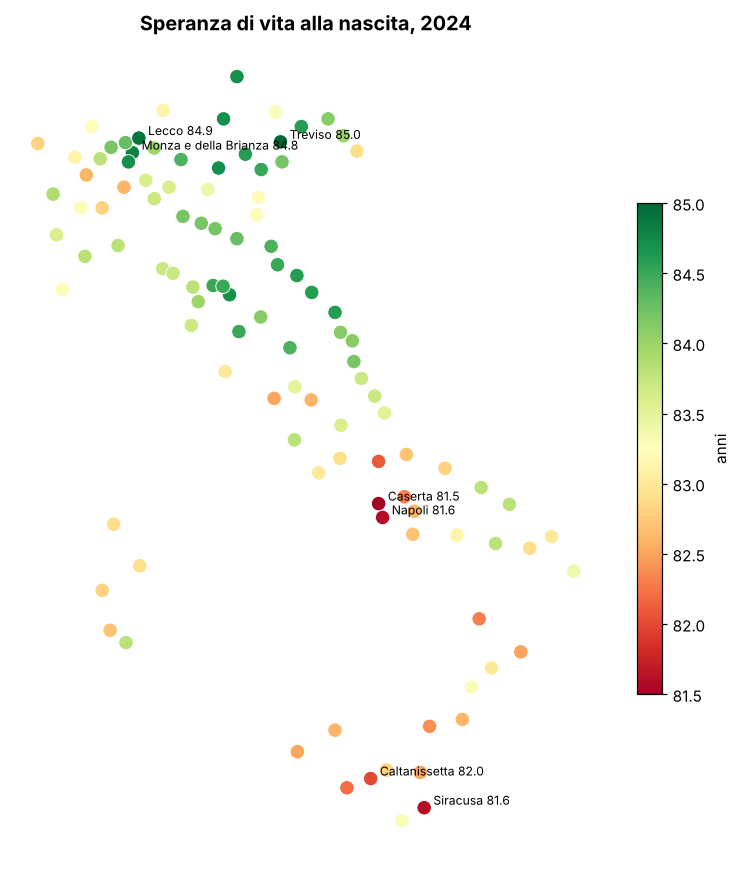

In [2]:
fig, ax = plt.subplots(figsize=(7, 8))
s = ax.scatter(p.longitudine, p.latitudine, c=p.vita_2024, cmap="RdYlGn", s=90, edgecolor="white", linewidth=0.6, vmin=81.5, vmax=85)
for _, r in p[p.posizione.le(3) | p.posizione.ge(104)].iterrows():
    ax.annotate(f"{r.provincia} {r.vita_2024:.1f}", (r.longitudine, r.latitudine), xytext=(6, 2), textcoords="offset points", fontsize=8)
plt.colorbar(s, ax=ax, shrink=0.6, label="anni")
ax.set_axis_off(); ax.set_title("Speranza di vita alla nascita, 2024")
salva("01_mappa_province")

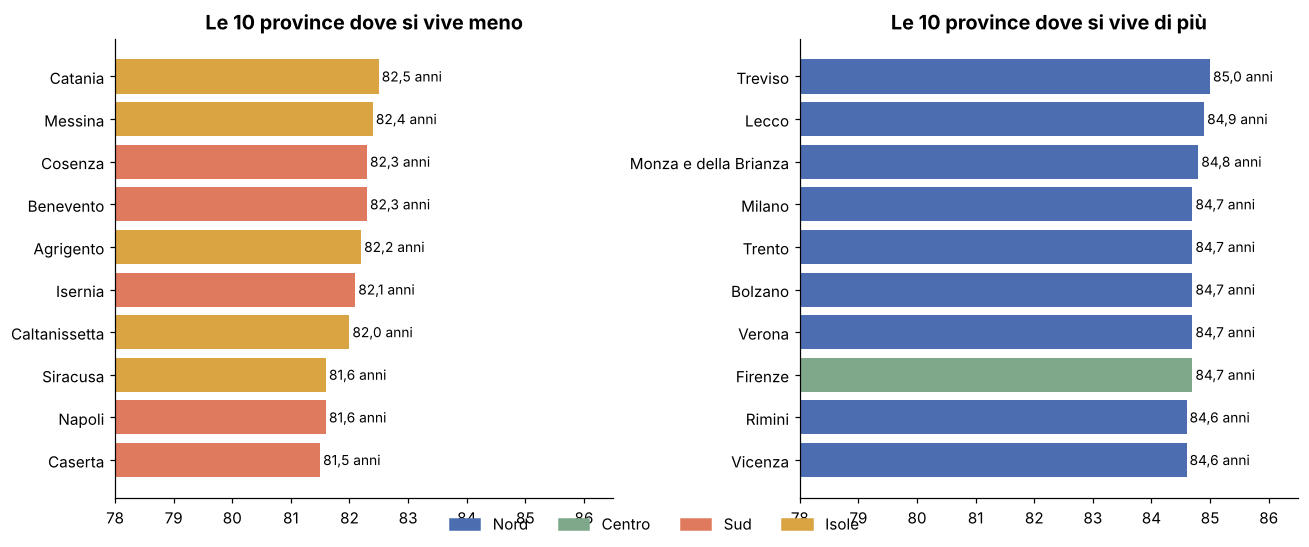

Differenza tra la prima e l'ultima: 3,5 anni
zona
Isole     82.6
Sud       83.0
Centro    84.0
Nord      84.0
Name: vita_2024, dtype: float64


In [3]:
o = p.sort_values("vita_2024")
fig, ax = plt.subplots(1, 2, figsize=(12, 5), sharex=True)
for a, d, tit in [(ax[0], o.head(10), "Le 10 province dove si vive meno"), (ax[1], o.tail(10), "Le 10 province dove si vive di più")]:
    a.barh(d.provincia, d.vita_2024, color=[ZONE[z] for z in d.zona])
    for y, v in enumerate(d.vita_2024): a.text(v + 0.05, y, anni(v), va="center", fontsize=9)
    a.set_title(tit); a.set_xlim(78, 86.5)
fig.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in ZONE.values()], labels=list(ZONE), loc="lower center", ncol=4, frameon=False)
plt.subplots_adjust(bottom=0.15); salva("02_province_estremi")
print("Differenza tra la prima e l'ultima:", anni(p.vita_2024.max() - p.vita_2024.min()))
print(p.groupby("zona").vita_2024.median().round(1).sort_values())

💡 **Cosa vediamo**

📌 In Italia si vive in media **83,5 anni** (2024).

📌 Si vive di più a **Treviso** (85,0), **Lecco** (84,9) e **Monza** (84,8). Di meno a **Caserta** (81,5), **Napoli** e **Siracusa** (81,6).

📌 Tra la prima e l'ultima provincia ci sono **3,5 anni** di differenza.

📌 Le province del **Nord** e del **Centro** vivono circa **1 anno in più** di quelle del Sud e delle Isole.

## 2️⃣ 💚 Quanti anni in buona salute?

📌 Questo dato c'è solo **per regione** (viene da un'indagine a campione, non da tutte le persone).

📌 Anni in buona salute + anni non in buona salute = speranza di vita.

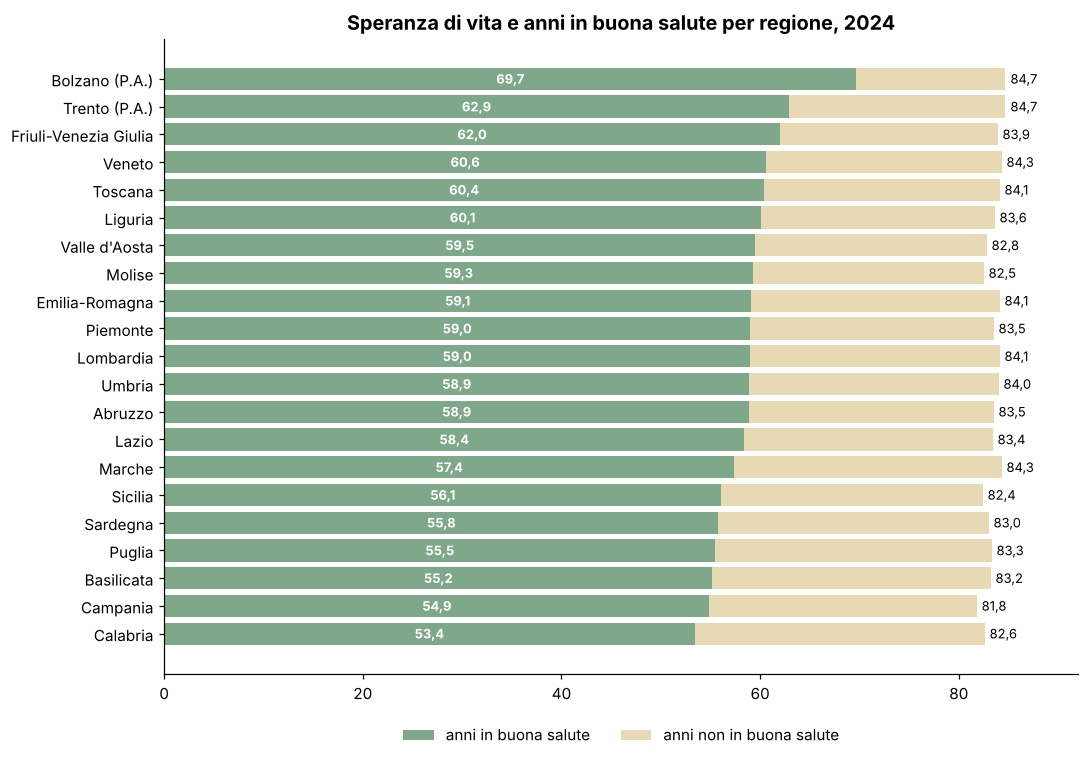

,regione,vita,buona_salute,non_buona_salute,pct_vita_buona_salute
4,Bolzano (P.A.),84.7,69.7,15.0,82.3
5,Trento (P.A.),84.7,62.9,21.8,74.3
7,Friuli-Venezia Giulia,83.9,62.0,21.9,73.9
6,Veneto,84.3,60.6,23.7,71.9
9,Toscana,84.1,60.4,23.7,71.8
2,Liguria,83.6,60.1,23.5,71.9
1,Valle d'Aosta,82.8,59.5,23.3,71.9
14,Molise,82.5,59.3,23.2,71.9
8,Emilia-Romagna,84.1,59.1,25.0,70.3
3,Lombardia,84.1,59.0,25.1,70.2


In [4]:
o = reg.sort_values("buona_salute")
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(o.regione, o.buona_salute, color=SALVIA, label="anni in buona salute")
ax.barh(o.regione, o.non_buona_salute, left=o.buona_salute, color=SABBIA, label="anni non in buona salute")
for y, (b, v) in enumerate(zip(o.buona_salute, o.vita)):
    ax.text(b / 2, y, f"{b:.1f}".replace(".", ","), va="center", ha="center", color="white", fontsize=8.5, fontweight="bold")
    ax.text(v + 0.5, y, f"{v:.1f}".replace(".", ","), va="center", fontsize=8.5)
ax.set_xlim(0, 92); ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.06), ncol=2); ax.set_title("Speranza di vita e anni in buona salute per regione, 2024")
salva("03_buona_salute_regioni")
reg.sort_values("buona_salute", ascending=False)[["regione", "vita", "buona_salute", "non_buona_salute", "pct_vita_buona_salute"]].round(1)

💡 **Cosa vediamo**

📌 La differenza di **anni in buona salute** è molto più grande di quella della durata della vita.

📌 A **Bolzano** si vivono **69,7 anni** in buona salute, in **Calabria** solo **53,4**: oltre **16 anni** di differenza.

📌 La speranza di vita invece cambia solo di 2-3 anni tra le regioni.

📌 In **Campania** si vive meno di tutti (81,8 anni) e solo il 67% della vita è in buona salute.

## 3️⃣ ⚖️ Nord e Sud, uomini e donne

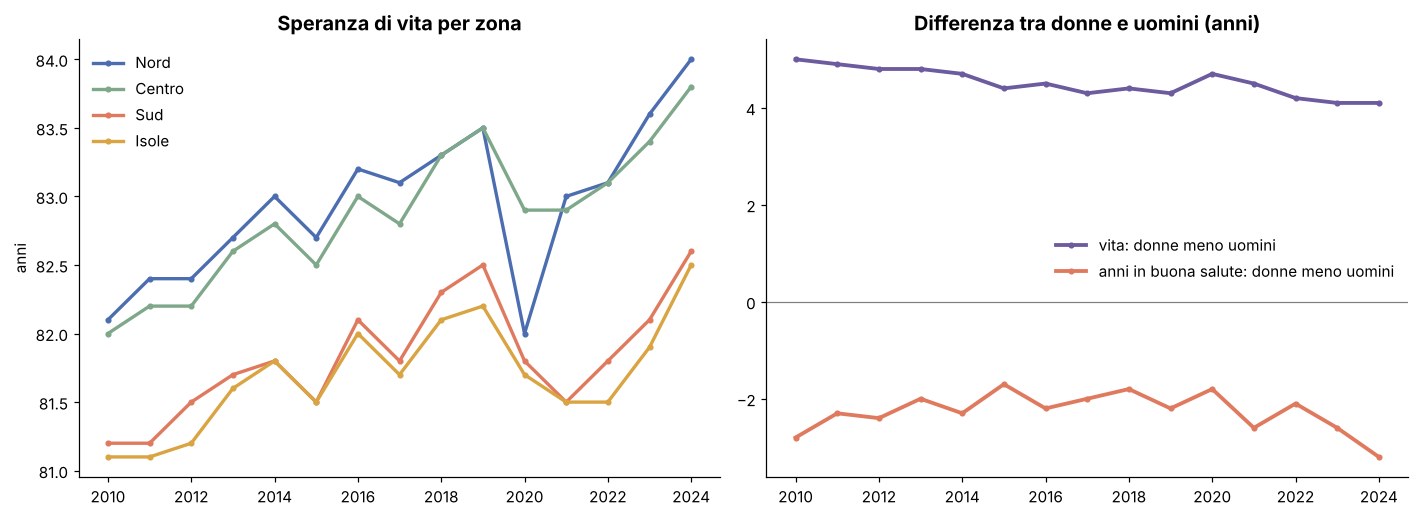

Distanza Nord-Sud 2010: 0,9 anni · 2024: 1,4 anni
Italia 2024 – vita: uomini 81,5 anni donne 85,6 anni
Italia 2024 – in buona salute: uomini 59,8 anni donne 56,6 anni


,provincia,vita_uomini_2024,vita_donne_2024,differenza_donne_uomini
104,Nuoro,79.7,86.3,6.6
106,Oristano,80.2,85.5,5.3
20,Sondrio,80.6,85.7,5.1
76,Campobasso,80.2,85.2,5.0
78,Benevento,79.9,84.9,5.0


In [5]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
z = za[(za.sesso == "T") & (za.territorio != "Italia")].pivot(index="anno", columns="territorio", values="speranza_vita")
for t in ["Nord", "Centro", "Sud", "Isole"]:
    ax[0].plot(z.index, z[t], marker="o", ms=3, lw=2.2, color=ZONE[t], label=t)
ax[0].set_title("Speranza di vita per zona"); ax[0].legend(frameon=False); ax[0].set_ylabel("anni")
g = za[(za.territorio == "Italia") & za.sesso.isin(["M", "F"])].pivot(index="anno", columns="sesso", values="speranza_vita")
h = za[(za.territorio == "Italia") & za.sesso.isin(["M", "F"])].pivot(index="anno", columns="sesso", values="anni_buona_salute")
ax[1].plot(g.index, g.F - g.M, color=LAVANDA, lw=2.5, marker="o", ms=3, label="vita: donne meno uomini")
ax[1].plot(h.index, h.F - h.M, color=CORALLO, lw=2.5, marker="o", ms=3, label="anni in buona salute: donne meno uomini")
ax[1].axhline(0, color="grey", lw=0.8); ax[1].legend(frameon=False); ax[1].set_title("Differenza tra donne e uomini (anni)")
salva("04_zone_sessi")
print("Distanza Nord-Sud 2010:", anni(z.loc[2010, "Nord"] - z.loc[2010, "Sud"]), "· 2024:", anni(z.loc[2024, "Nord"] - z.loc[2024, "Sud"]))
it3 = za[(za.territorio == "Italia") & (za.anno == 2024)].set_index("sesso")
print("Italia 2024 – vita:", "uomini", anni(it3.loc["M", "speranza_vita"]), "donne", anni(it3.loc["F", "speranza_vita"]))
print("Italia 2024 – in buona salute:", "uomini", anni(it3.loc["M", "anni_buona_salute"]), "donne", anni(it3.loc["F", "anni_buona_salute"]))
p.sort_values("differenza_donne_uomini", ascending=False)[["provincia", "vita_uomini_2024", "vita_donne_2024", "differenza_donne_uomini"]].head(5)

💡 **Cosa vediamo**

📌 **Nord** e **Centro** restano davanti. La distanza tra Nord e **Sud** è cresciuta: da **0,9** anni nel 2010 a **1,4** nel 2024.

📌 Le **donne** vivono circa **4 anni in più** degli uomini (85,6 contro 81,5 nel 2024).

📌 Ma **in buona salute** vivono **meno** degli uomini: 56,6 anni contro 59,8. Vivono di più, ma più anni con problemi di salute.

📌 La distanza tra donne e uomini si sta **riducendo**: da 5,0 anni nel 2010 a 4,1 nel 2024, perché gli uomini guadagnano più anni.

## 4️⃣ 📈 Dal 2010 a oggi, Covid compreso

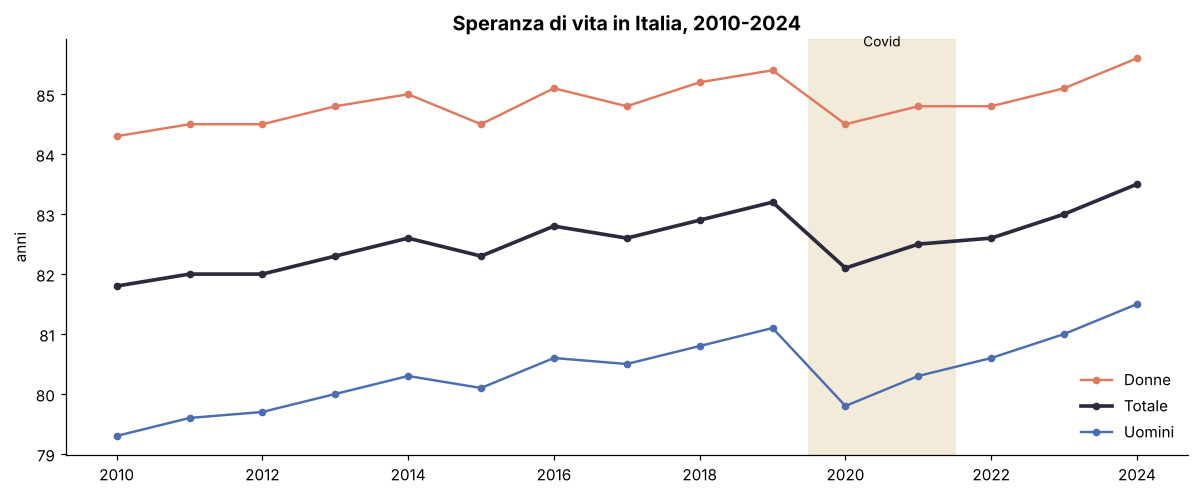

Italia: 2010 81,8 anni · 2019 83,2 anni · 2020 82,1 anni · 2024 83,5 anni


In [6]:
fig, ax = plt.subplots(figsize=(11, 4.6))
for s, c, n in [("F", CORALLO, "Donne"), ("T", INCHIOSTRO, "Totale"), ("M", "#4C6EB1", "Uomini")]:
    d = za[(za.territorio == "Italia") & (za.sesso == s)]
    ax.plot(d.anno, d.speranza_vita, marker="o", ms=4, lw=2.4 if s == "T" else 1.6, color=c, label=n)
ax.axvspan(2019.5, 2021.5, color=SABBIA, alpha=0.5); ax.text(2020.5, 85.8, "Covid", ha="center", fontsize=9)
ax.set_title("Speranza di vita in Italia, 2010-2024"); ax.legend(frameon=False); ax.set_ylabel("anni")
salva("05_italia_anni")
print("Italia: 2010", anni(it.loc[2010, "speranza_vita"]), "· 2019", anni(it.loc[2019, "speranza_vita"]),
      "· 2020", anni(it.loc[2020, "speranza_vita"]), "· 2024", anni(it.loc[2024, "speranza_vita"]))

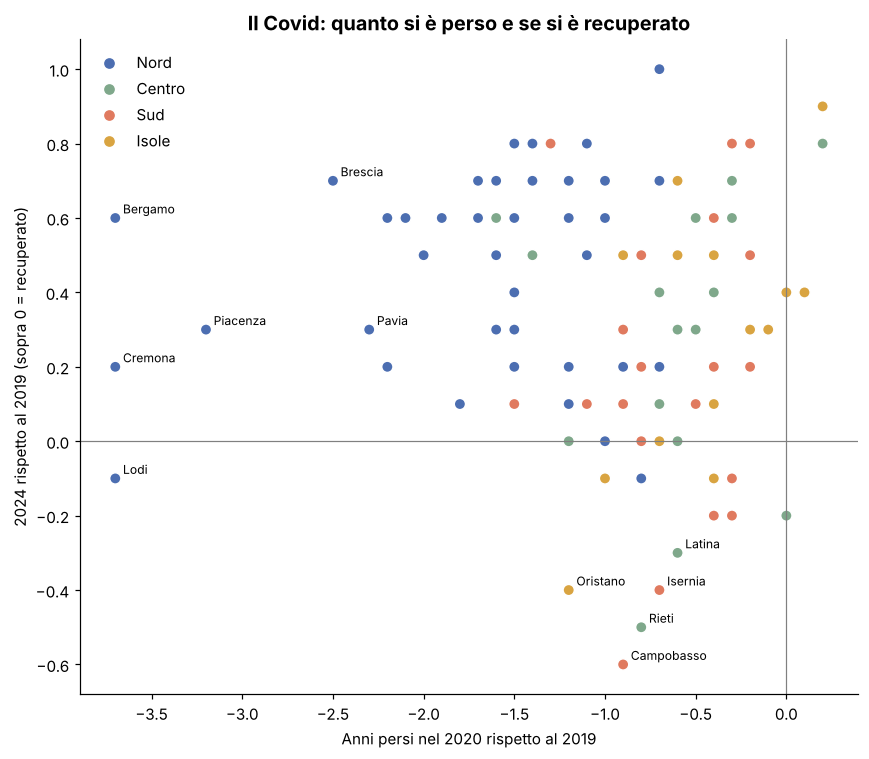

Province che nel 2024 non sono ancora tornate al 2019: 14


,provincia,zona,vita_2019,vita_2020,calo_covid_2020,vita_2024
25,Lodi,Nord,83.7,80.0,-3.7,83.6
26,Cremona,Nord,83.4,79.7,-3.7,83.6
22,Bergamo,Nord,83.4,79.7,-3.7,84.0
41,Piacenza,Nord,83.4,80.2,-3.2,83.7
23,Brescia,Nord,83.7,81.2,-2.5,84.4
24,Pavia,Nord,82.3,80.0,-2.3,82.6


In [7]:
fig, ax = plt.subplots(figsize=(8, 7))
ax.scatter(p.calo_covid_2020, p.recupero_2024_vs_2019, c=[ZONE[z] for z in p.zona], s=55, edgecolor="white")
for _, r in p[p.calo_covid_2020.le(-2.3) | p.recupero_2024_vs_2019.le(-0.3)].iterrows():
    ax.annotate(r.provincia, (r.calo_covid_2020, r.recupero_2024_vs_2019), xytext=(5, 3), textcoords="offset points", fontsize=8)
ax.axhline(0, color="grey", lw=0.8); ax.axvline(0, color="grey", lw=0.8)
ax.set_xlabel("Anni persi nel 2020 rispetto al 2019"); ax.set_ylabel("2024 rispetto al 2019 (sopra 0 = recuperato)")
ax.set_title("Il Covid: quanto si è perso e se si è recuperato")
ax.legend(handles=[plt.Line2D([], [], marker="o", ls="", color=c) for c in ZONE.values()], labels=list(ZONE), frameon=False)
salva("06_covid")
print("Province che nel 2024 non sono ancora tornate al 2019:", int((p.recupero_2024_vs_2019 < 0).sum()))
p.sort_values("calo_covid_2020")[["provincia", "zona", "vita_2019", "vita_2020", "calo_covid_2020", "vita_2024"]].head(6)

💡 **Cosa vediamo**

📌 Dal 2010 al 2019 la speranza di vita è salita di **1,4 anni** (da 81,8 a 83,2).

📌 Nel **2020** il Covid l'ha fatta scendere di **1,1 anni** in un solo anno (82,1).

📌 Il calo più forte è stato in **Lombardia ed Emilia**: **Lodi, Cremona e Bergamo** hanno perso **3,7 anni**.

📌 Nel **2024** l'Italia ha superato il livello di prima del Covid: **83,5 anni**.

📌 **93 province su 107** sono tornate almeno al livello del 2019. Le altre 14 sono ancora un po' sotto.

## 5️⃣ 🚬 Gli stili di vita c'entrano?

📌 Confronto per regione: **anni in buona salute** e quanto le persone fanno sport, sono in sovrappeso o fumano.

📌 **Spearman** misura se due cose vanno insieme (da −1 a +1).

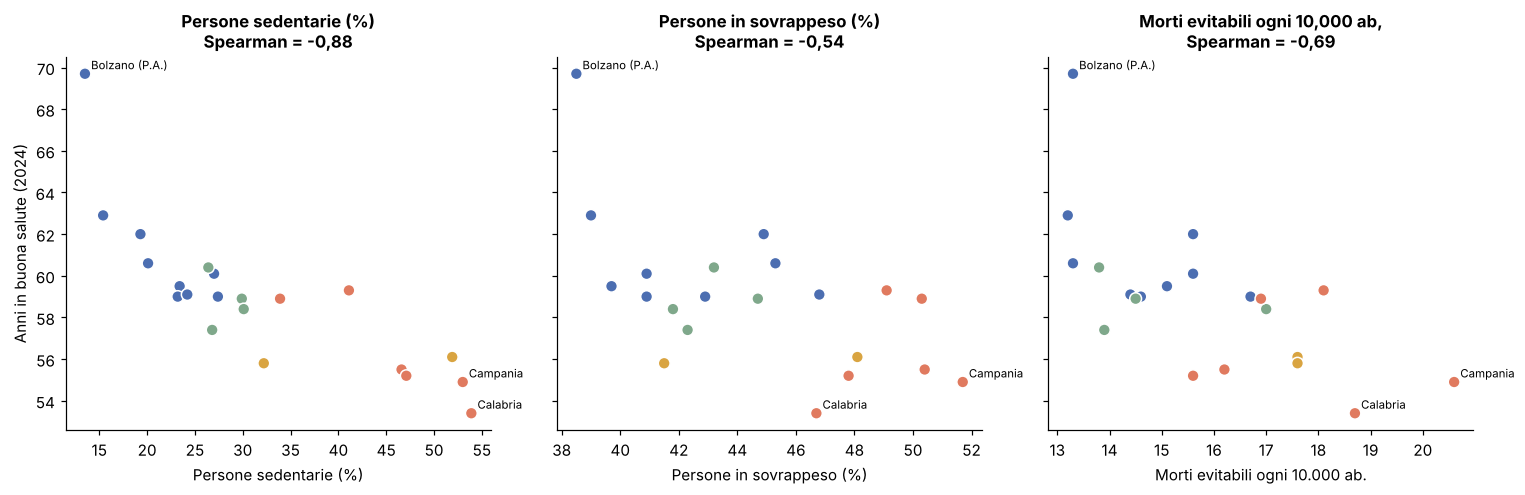

sedentarieta          -0.88
mortalita_evitabile   -0.69
eccesso_peso          -0.54
fumo                  -0.50
buona_alimentazione    0.61
alcol                  0.74
Name: Spearman con anni in buona salute, dtype: float64

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4.6), sharey=True)
for a, c, tit in [(ax[0], "sedentarieta", "Persone sedentarie (%)"), (ax[1], "eccesso_peso", "Persone in sovrappeso (%)"),
                  (ax[2], "mortalita_evitabile", "Morti evitabili ogni 10.000 ab.")]:
    a.scatter(reg[c], reg.buona_salute, c=[ZONE[z] for z in reg.zona], s=60, edgecolor="white")
    rho = stats.spearmanr(reg[c], reg.buona_salute)[0]
    a.set_title(f"{tit}\nSpearman = {rho:.2f}".replace(".", ","), fontsize=11); a.set_xlabel(tit)
    for _, r in reg[reg.regione.isin(["Bolzano (P.A.)", "Calabria", "Campania"])].iterrows():
        a.annotate(r.regione, (r[c], r.buona_salute), xytext=(4, 3), textcoords="offset points", fontsize=7.5)
ax[0].set_ylabel("Anni in buona salute (2024)")
salva("07_stili_di_vita")
corr = {c: stats.spearmanr(reg[c], reg.buona_salute)[0] for c in ["sedentarieta", "eccesso_peso", "fumo", "alcol", "mortalita_evitabile", "buona_alimentazione"]}
pd.Series(corr, name="Spearman con anni in buona salute").round(2).sort_values()

💡 **Cosa vediamo**

📌 Dove ci sono più persone **sedentarie** e **in sovrappeso**, gli anni in buona salute sono **meno** (legame forte e negativo).

📌 Anche le **morti evitabili** (con prevenzione e cure tempestive) vanno insieme a meno anni in buona salute.

📌 Anche il **fumo** va insieme a meno anni in buona salute, ma il legame è più debole.

📌 Curiosità: dove si beve più **alcol** (soprattutto al Nord) gli anni in buona salute sono di più. È un esempio di cose che vanno insieme senza che una sia la causa dell'altra.

⚠️ Andare insieme **non** vuol dire essere la causa: contano anche il reddito, lo studio e la sanità.

## ✅ Conclusioni

1️⃣ 🗺️ In Italia si vive **83,5 anni**. Da **85,0** a Treviso a **81,5** a Caserta: **3,5 anni** di differenza.

2️⃣ 💚 Gli anni **in buona salute** cambiano molto di più: da **69,7** a Bolzano a **53,4** in Calabria (**16 anni**).

3️⃣ ⚖️ Il Nord vive **1,4 anni** in più del Sud, e la distanza è cresciuta dal 2010. Le donne vivono **4 anni** in più, ma meno anni in buona salute degli uomini.

4️⃣ 📈 Il **Covid** ha tolto **1,1 anni** nel 2020 (fino a 3,7 nel Lodigiano e nella Bergamasca). Nel 2024 si è tornati sopra il livello del 2019.

5️⃣ 🚬 Meno sport e più chili vanno insieme a meno anni in buona salute.

⚠️ Limiti: gli anni in buona salute ci sono solo per regione e dipendono da come le persone giudicano la propria salute.